[[1 2]
 [2 1]
 [2 3]
 [3 2]
 [8 8]
 [9 8]
 [8 9]
 [9 9]]
[[1. 1. 2.]
 [1. 2. 1.]
 [1. 2. 3.]
 [1. 3. 2.]
 [1. 8. 8.]
 [1. 9. 8.]
 [1. 8. 9.]
 [1. 9. 9.]]
[np.float64(0.6931471805599453), np.float64(0.5673092590265855), np.float64(0.5358829840418604), np.float64(0.5284678488306968), np.float64(0.5234144943784484), np.float64(0.5184377062545529), np.float64(0.5135244706989461), np.float64(0.5086740755487718), np.float64(0.5038858073083605), np.float64(0.4991589516460321), np.float64(0.49449279385573475), np.float64(0.4898866193024551), np.float64(0.4853397138511555), np.float64(0.4808513642792563), np.float64(0.47642085867270895), np.float64(0.4720474868057525), np.float64(0.4677305405044704), np.float64(0.46346931399430535), np.float64(0.4592631042317094), np.float64(0.45511121122014053), np.float64(0.4510129383106373), np.float64(0.4469675924872266), np.float64(0.44297448463743905), np.float64(0.439032929808223), np.float64(0.4351422474475696), np.float64(0.4313017616321634), np.float6

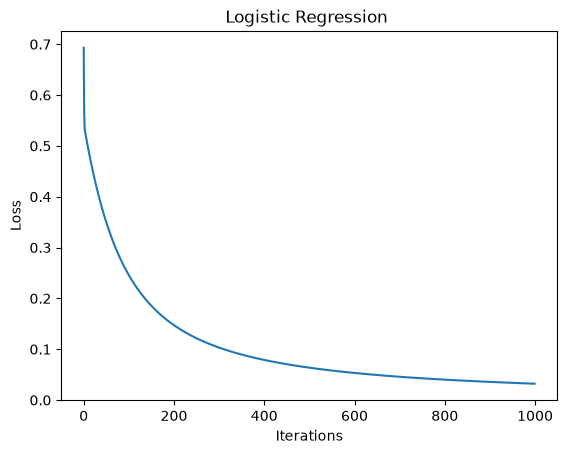

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample binary dataset

X = np.array([[1,2],[2,1],[2,3],[3,2],[8,8],[9,8],[8,9],[9,9]])
print(X)
y = np.array([0,0,0,0,1,1,1,1])

# add a bias term
X_b = np.c_[np.ones((X.shape[0],1)),X]
print(X_b)

# 1/(1+e^-x)
# sigmoid function
def sigmoid(z):
  return (1/(1+np.exp(-z)))

# logistic regression using Gradient Descent
def logistic_regression(X,y, lr=0.1,epochs=1000):
  theta= np.zeros(X.shape[1])  #initialize weights

  m=len(y)

  losses=[]

  for _ in range(epochs):
    # m1X1 + m2X2

    z = X.dot(theta)
    h=sigmoid(z)

    gradient = (1/m)* X.T.dot(h-y)
    theta = theta - lr * gradient

    loss = -(1/m) * np.sum(y*np.log(h) + (1-y)* np.log(1-h))
    # print(loss)
    losses.append(loss)
  print(losses)
  return theta, losses


theta,losses= logistic_regression(X_b,y)
print('Learned parameters:',theta )

plt.plot(losses)
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Logistic Regression ')
plt.show()

In [2]:
#Bayes Theorem
# Naive Bayes Classifier

# The "Naive" Assumption

# -> Assumes all features are independent given the class
# Example: spam detection ... words like 'free','offer','win' are assumed independent


# Type of Naive Bayes

# 1) Gaussian Naive Bayes -> Continuous features(assumes normal distribution)
# 2) Multinomial Naive Bayes -> Discrete counts( word frequency , text data)
# 3) Bernoulli Naive Bayes -> Binary features (word present/absent )


In [3]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

#sample dataset

data={
    "text":[
        "free money offer now",
        "win lottery cash prize",
        "meeting schedule today",
        "project deadline tommorow",
        "exclusive offer just for you",
        "let's discuss work progress"
    ],
    "label": ["spam","spam","ham","ham","spam","ham"]
}
df=pd.DataFrame(data)

#convert text to word(data)
vectorizer=CountVectorizer()
X=vectorizer.fit_transform(df['text'])
#print(X)
y=df['label']

#train-test-split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

#Naive Bayes model
nb=MultinomialNB()
nb.fit(X_train,y_train)

#predictions
y_pred=nb.predict(X_test)

print('Accuracy:',accuracy_score(y_test,y_pred))

Accuracy: 0.5
